<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Detecci%C3%B3n_de_Fuego_y_Humo_con_Yolo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔥 Le enseñé a una IA a detectar fuego y humo antes que la alarma
**Laboratorio de Códigos** · YOLO + Colab

1. `Entorno de ejecución → Cambiar tipo de entorno → GPU T4`
2. Guarda tu API key de Roboflow en **Secretos** (ícono 🔑 a la izquierda) con el nombre `ROBOFLOW_API_KEY` y activa el acceso del notebook. Así no aparece en pantalla al grabar.
3. Sube un video de prueba con fuego o humo (o usa uno libre de derechos).

In [ ]:
!pip install -q ultralytics roboflow

## 1. Dataset de fuego y humo
En [Roboflow Universe](https://universe.roboflow.com) busca **"fire smoke"**, elige un dataset con las clases *fire* y *smoke*, y en **Download Dataset → YOLOv8 → Show download code** copia los valores de `workspace`, `project` y `version` aquí abajo.

In [ ]:
from google.colab import userdata
from roboflow import Roboflow

WORKSPACE = "firesmoke"   # <- del código de descarga de Roboflow
PROYECTO  = "fire-smoke-dfzrj"
VERSION   = 9

rf = Roboflow(api_key=userdata.get("ROBOFLOW"))
dataset = rf.workspace(WORKSPACE).project(PROYECTO).version(VERSION).download("yolov8")
print("Dataset en:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fire-smoke-9 in yolov8:: 100%|██████████| 13724/13724 [00:01<00:00, 9657.33it/s] 


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset en: /content/fire-smoke-9


In [ ]:
# Arreglo de rutas: Roboflow a veces deja rutas relativas que Ultralytics no encuentra
import os, yaml

ruta_yaml = os.path.join(dataset.location, "data.yaml")
cfg = yaml.safe_load(open(ruta_yaml))
for split, carpeta in (("train", "train"), ("val", "valid"), ("test", "test")):
    d = os.path.join(dataset.location, carpeta, "images")
    if os.path.isdir(d):
        cfg[split] = d
yaml.safe_dump(cfg, open(ruta_yaml, "w"))
print("Clases:", cfg["names"])

Clases: ['fire', 'smoke']


Mostrando un lote de imágenes de entrenamiento con sus etiquetas (bounding boxes):


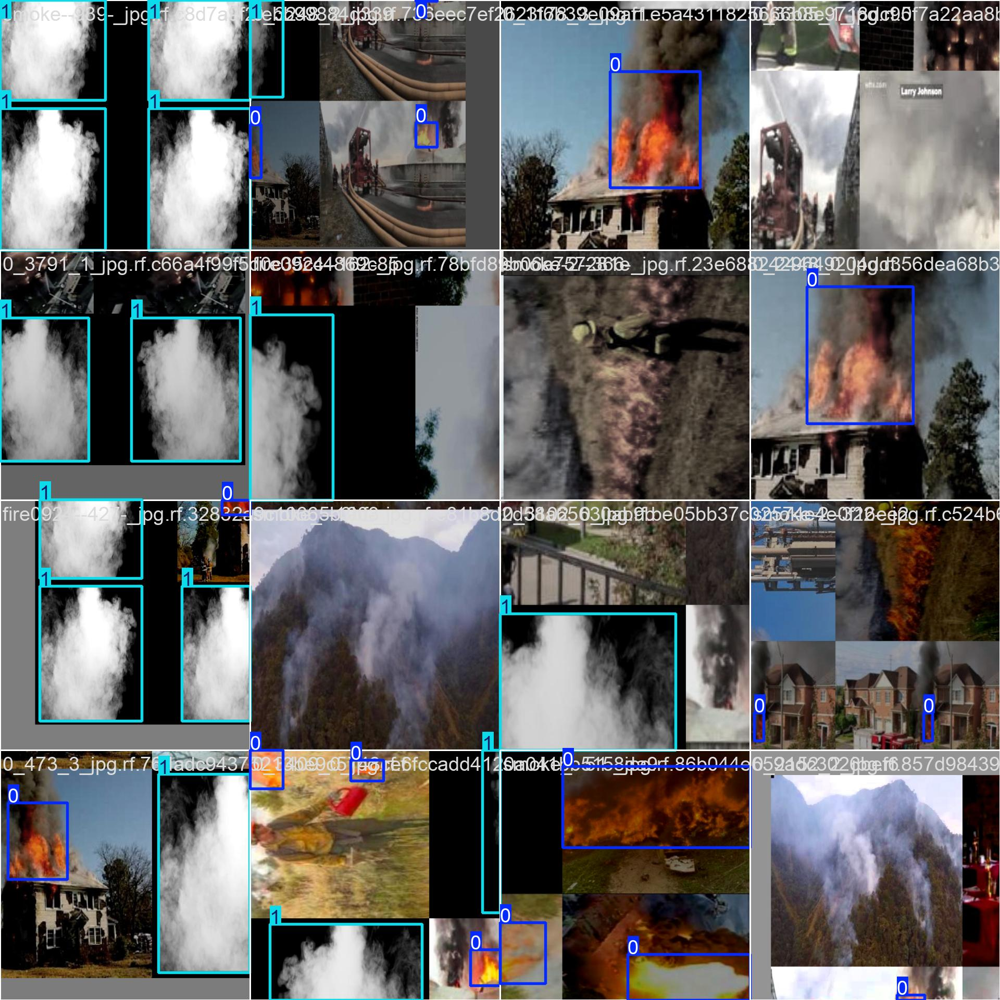

In [ ]:
import os
from IPython.display import Image, display

# Definir una ruta por defecto por si la celda de entrenamiento no se ha ejecutado aún o se reinició el entorno
if 'carpeta_run' not in globals():
    carpeta_run = "/content/runs/detect/fuego_humo"

# Ruta de la imagen de lote de entrenamiento generada por YOLO que contiene las etiquetas
ruta_lote = os.path.join(carpeta_run, "train_batch0.jpg")

if os.path.exists(ruta_lote):
    print("Mostrando un lote de imágenes de entrenamiento con sus etiquetas (bounding boxes):")
    display(Image(filename=ruta_lote, width=900))
else:
    print(f"No se encontró el archivo train_batch0.jpg en el directorio: {carpeta_run}")
    print("Asegúrate de ejecutar primero la celda de entrenamiento.")

## 2. Entrenamiento
Con una T4, 30 épocas del modelo *nano* tardan unos minutos según el tamaño del dataset. Si tu versión de Ultralytics no tiene YOLO26, cambia a `yolo11n.pt`.

In [ ]:
from ultralytics import YOLO

modelo = YOLO("yolo26n.pt")
modelo.train(data=ruta_yaml, epochs=15, imgsz=640, batch=16, name="fuego_humo")

carpeta_run = modelo.trainer.save_dir
mejor = YOLO(os.path.join(carpeta_run, "weights", "best.pt"))
metricas = mejor.val(data=ruta_yaml)
print(f"mAP50: {metricas.box.map50:.3f}   mAP50-95: {metricas.box.map:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire-smoke-9/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fuego_humo, nbs=64, nms=None, opset=None, optimize=False,

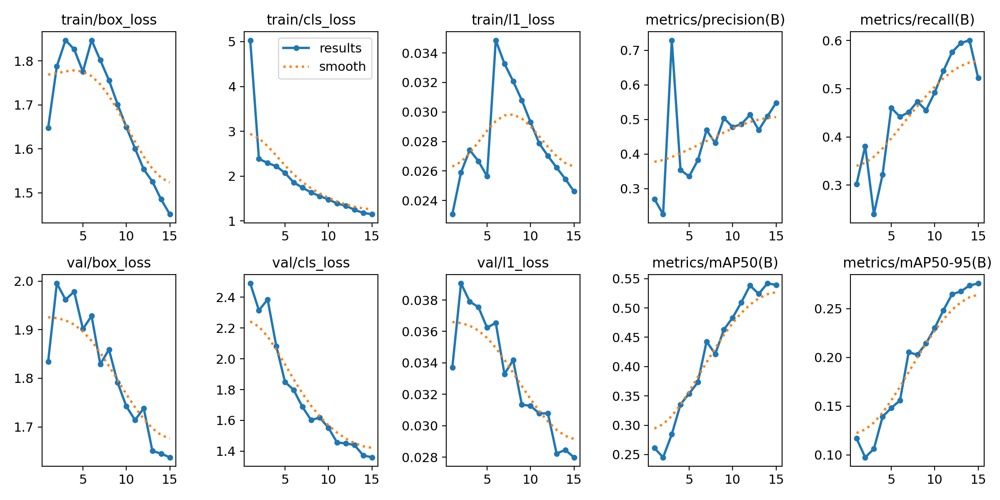

In [ ]:
# Curvas de entrenamiento (buen plano para el video)
from IPython.display import Image, display
display(Image(filename=os.path.join(carpeta_run, "results.png"), width=900))

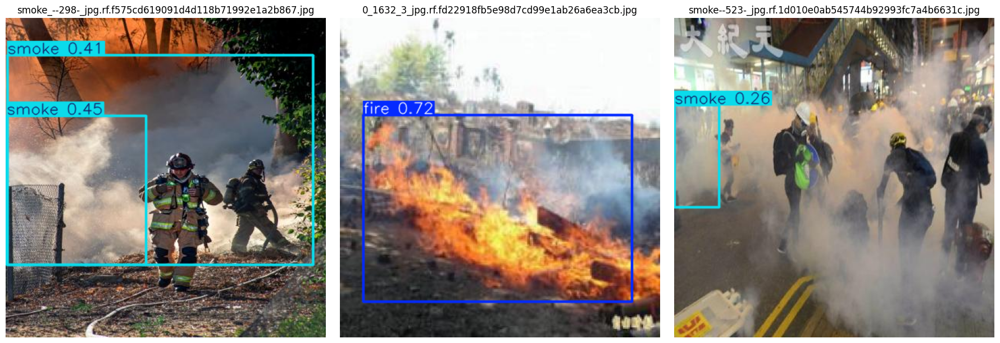

In [ ]:
import os
import glob
from PIL import Image
import matplotlib.pyplot as plt

# Obtener imágenes de la carpeta de prueba
imagenes_prueba = glob.glob(os.path.join(dataset.location, "test", "images", "*"))[:3]

if not imagenes_prueba:
    print("No se encontraron imágenes en la carpeta de prueba.")
else:
    fig, axes = plt.subplots(1, len(imagenes_prueba), figsize=(18, 6))
    if len(imagenes_prueba) == 1:
        axes = [axes]

    for ax, ruta_img in zip(axes, imagenes_prueba):
        # Realizar la predicción con el mejor modelo guardado
        resultado = mejor.predict(source=ruta_img, conf=0.25, verbose=False)[0]

        # Dibujar las detecciones sobre la imagen
        img_pred = resultado.plot()

        # Mostrar la imagen con matplotlib (convertir BGR de OpenCV a RGB)
        ax.imshow(img_pred[..., ::-1])
        ax.axis("off")
        ax.set_title(os.path.basename(ruta_img))

    plt.tight_layout()
    plt.show()

In [ ]:
from google.colab import files
import os

# Ruta al mejor archivo de pesos (.pt) generado durante el entrenamiento
ruta_mejor_modelo = os.path.join(carpeta_run, "weights", "best.pt")

if os.path.exists(ruta_mejor_modelo):
    print(f"Descargando el mejor modelo desde: {ruta_mejor_modelo}")
    files.download(ruta_mejor_modelo)
else:
    print("No se encontró el archivo 'best.pt' en la carpeta de entrenamiento.")

Descargando el mejor modelo desde: /content/runs/detect/fuego_humo/weights/best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3. La prueba: video con alerta
La alerta se activa cuando la IA ve fuego o humo durante varios cuadros seguidos, para evitar falsas alarmas por un solo cuadro.

In [ ]:
from google.colab import files
subido = files.upload()              # sube tu video de prueba
VIDEO_IN = next(iter(subido))

Saving 204361-924209264_medium.mp4 to 204361-924209264_medium.mp4


In [ ]:
import cv2

CONF = 0.40                # confianza mínima
CUADROS_PARA_ALERTA = 8    # cuadros seguidos con detección
PALABRAS = ("fire", "smoke", "fuego", "humo")

cap = cv2.VideoCapture(VIDEO_IN)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
out = cv2.VideoWriter("salida_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

racha, cuadro, t_alerta = 0, 0, None
while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = mejor.predict(frame, conf=CONF, verbose=False)[0]
    clases = [r.names[int(c)].lower() for c in r.boxes.cls]
    hay_fuego = any(p in c for c in clases for p in PALABRAS)
    racha = racha + 1 if hay_fuego else 0

    img = r.plot()
    if racha >= CUADROS_PARA_ALERTA:
        if t_alerta is None:
            t_alerta = cuadro / fps
        cv2.rectangle(img, (0, 0), (w, 80), (0, 0, 255), -1)
        cv2.putText(img, "ALERTA: FUEGO / HUMO", (20, 55), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (255, 255, 255), 4)
    else:
        cv2.rectangle(img, (0, 0), (w, 60), (40, 140, 40), -1)
        cv2.putText(img, "Monitoreando...", (20, 42), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 3)
    out.write(img)
    cuadro += 1

cap.release(); out.release()
print("Primera alerta en el segundo:", None if t_alerta is None else round(t_alerta, 1))

Primera alerta en el segundo: 0.7


In [ ]:
# Convertir a H.264 para verlo en Colab y subirlo a TikTok
!ffmpeg -y -loglevel error -i salida_raw.mp4 -c:v libx264 -preset veryfast -pix_fmt yuv420p alerta_fuego.mp4

from base64 import b64encode
from IPython.display import HTML
datos = b64encode(open("alerta_fuego.mp4", "rb").read()).decode()
HTML(f'<video width=720 controls autoplay loop><source src="data:video/mp4;base64,{datos}" type="video/mp4"></video>')

In [ ]:
files.download("alerta_fuego.mp4")